# Cash Flow Copilot — Step 1: EDA & Target Definition
الهدف: نفهم الداتا، نتأكد إنها سليمة، ونعرّف الـ targets (late invoice + cash shortage) ونجهز الـ time-based split.

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (10, 4)

DATA_DIR = "data"   # غيّر المسار لو الـ CSVs في مكان تاني
cf  = pd.read_csv(f"{DATA_DIR}/synthetic_sme_daily_cash_flow.csv", parse_dates=["date"])
inv = pd.read_csv(f"{DATA_DIR}/synthetic_sme_invoices.csv", parse_dates=["invoice_date","due_date","paid_date"])
pay = pd.read_csv(f"{DATA_DIR}/synthetic_sme_payments.csv", parse_dates=["payment_date"])
exp = pd.read_csv(f"{DATA_DIR}/synthetic_sme_expenses.csv", parse_dates=["date"])
for n, d in [("cash_flow",cf),("invoices",inv),("payments",pay),("expenses",exp)]:
    print(f"{n:10s}", d.shape)

cash_flow  (8768, 22)
invoices   (8768, 11)
payments   (8764, 6)
expenses   (7636, 5)


## 1) Data quality checks

In [7]:
checks = {
 "net = inflow - outflow": (cf.total_cash_inflow_egp - cf.total_cash_outflow_egp - cf.net_cash_flow_egp).abs().max(),
 "inflow parts sum":       (cf.cash_sales_egp + cf.receivables_collected_egp + cf.other_income_egp - cf.total_cash_inflow_egp).abs().max(),
 "balance chain":          (cf.groupby("business_id").closing_cash_balance_egp.shift() + cf.net_cash_flow_egp - cf.closing_cash_balance_egp).abs().max(),
}
for k, v in checks.items(): print(f"{k:25s} max error = {v:.2e}")
print("\nDate range:", cf.date.min().date(), "->", cf.date.max().date())
print("Days per business:", cf.groupby("business_id").size().unique())
print("Duplicates:", cf.duplicated(["business_id","date"]).sum())
print("Missing paid_date (outstanding):", inv.paid_date.isna().sum())
print("Min closing balance ever:", round(cf.closing_cash_balance_egp.min()))

net = inflow - outflow    max error = 7.28e-12
inflow parts sum          max error = 7.28e-12
balance chain             max error = 4.66e-10

Date range: 2023-01-01 -> 2025-12-31
Days per business: [1096]
Duplicates: 0
Missing paid_date (outstanding): 4
Min closing balance ever: 81155


## 2) Businesses overview

In [8]:
summary = cf.groupby(["business_id","sector"]).agg(
    avg_daily_sales=("sales_egp","mean"),
    avg_daily_net=("net_cash_flow_egp","mean"),
    min_balance=("closing_cash_balance_egp","min"),
    avg_balance=("closing_cash_balance_egp","mean")).round(0)
summary

,,avg_daily_sales,avg_daily_net,min_balance,avg_balance
business_id,sector,,,,
SME_001,Wholesale,15090.0,3080.0,191695.0,1895024.0
SME_002,Retail,8002.0,1640.0,91020.0,991927.0
SME_003,Services,5950.0,1357.0,122691.0,781357.0
SME_004,Distribution,18188.0,2464.0,241849.0,1446155.0
SME_005,Ecommerce,9164.0,1690.0,105427.0,1034162.0
SME_006,Wholesale,12950.0,3019.0,161386.0,1720142.0
SME_007,Services,7264.0,1652.0,81155.0,947137.0
SME_008,Retail,10250.0,1858.0,133527.0,1211928.0


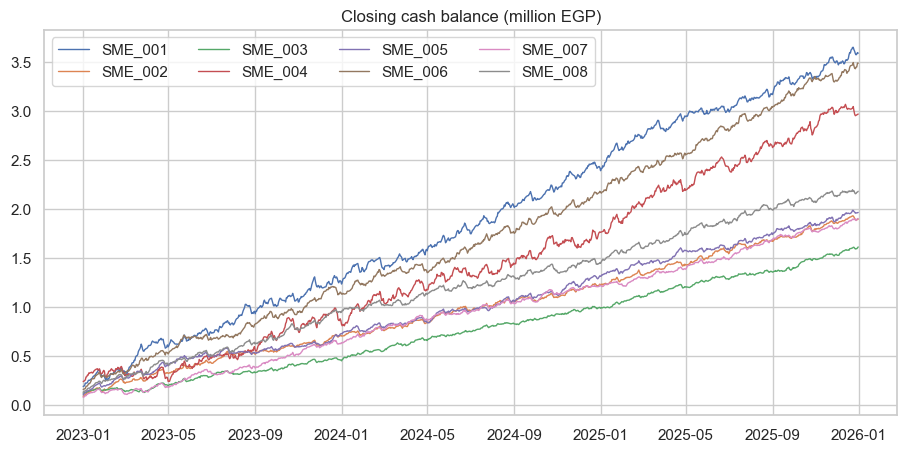

In [9]:
fig, ax = plt.subplots(figsize=(11,5))
for b, g in cf.groupby("business_id"): ax.plot(g.date, g.closing_cash_balance_egp/1e6, label=b, lw=1)
ax.set_title("Closing cash balance (million EGP)"); ax.legend(ncol=4); plt.show()

## 3) Seasonality & drivers

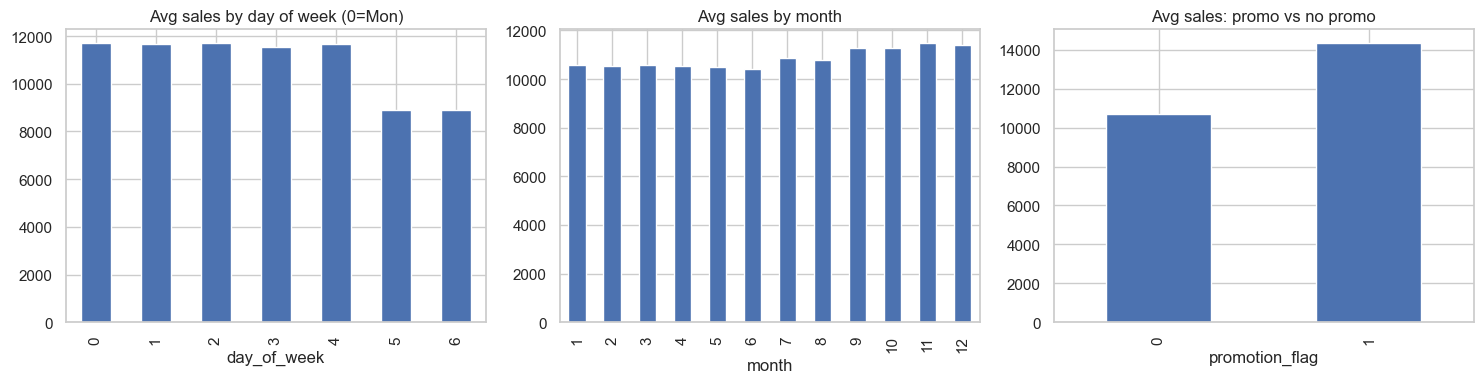

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15,4))
cf.groupby("day_of_week").sales_egp.mean().plot.bar(ax=axs[0], title="Avg sales by day of week (0=Mon)")
cf.groupby("month").sales_egp.mean().plot.bar(ax=axs[1], title="Avg sales by month")
cf.groupby("promotion_flag").sales_egp.mean().plot.bar(ax=axs[2], title="Avg sales: promo vs no promo")
plt.tight_layout(); plt.show()

In [11]:
# Lumpy outflows: when do payroll / rent / loans / taxes happen?
for c in ["payroll_egp","rent_egp","loan_payments_egp","taxes_egp"]:
    days = cf.loc[cf[c] > 0, "date"].dt.day
    print(f"{c:20s} paid on {len(days)} days | most common day-of-month: {days.value_counts().head(3).to_dict()}")

payroll_egp          paid on 864 days | most common day-of-month: {25: 288, 26: 288, 27: 288}
rent_egp             paid on 288 days | most common day-of-month: {1: 288}
loan_payments_egp    paid on 288 days | most common day-of-month: {10: 288}
taxes_egp            paid on 96 days | most common day-of-month: {15: 96}


## 4) Late-invoice analysis (Target A)

Late rate (paid invoices): 0.189
count    1601.0
mean       19.5
std        17.7
min         3.0
25%         7.0
50%        14.0
75%        30.0
max        60.0
Name: payment_delay_days, dtype: float64


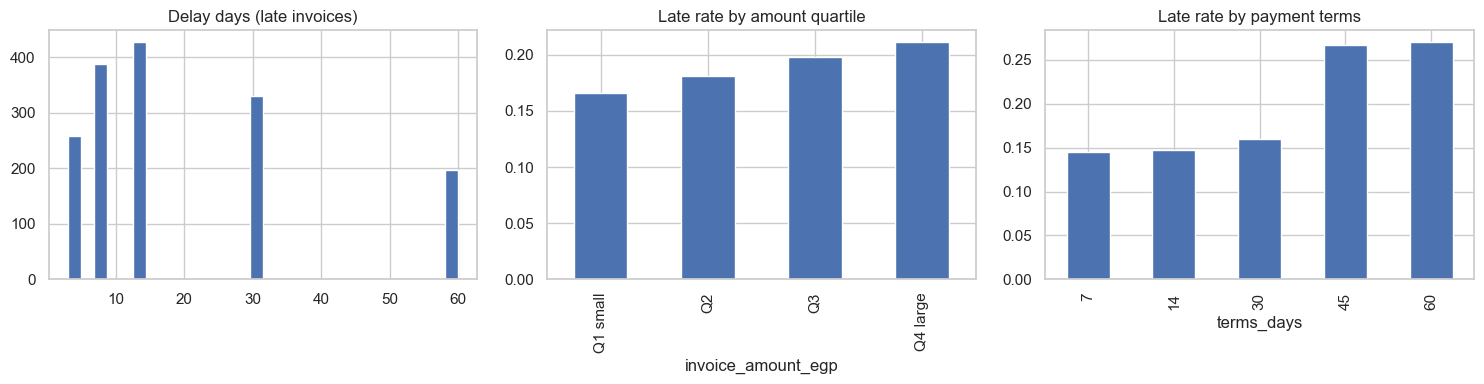

In [12]:
paid = inv[inv.status == "paid"].copy()
paid["terms_days"] = (paid.due_date - paid.invoice_date).dt.days
print("Late rate (paid invoices):", round(paid.is_late.mean(), 3))
print(paid.loc[paid.is_late == 1, "payment_delay_days"].describe().round(1))

fig, axs = plt.subplots(1, 3, figsize=(15,4))
paid.loc[paid.is_late==1,"payment_delay_days"].hist(bins=30, ax=axs[0]); axs[0].set_title("Delay days (late invoices)")
paid.groupby(pd.qcut(paid.invoice_amount_egp, 4, labels=["Q1 small","Q2","Q3","Q4 large"])).is_late.mean().plot.bar(ax=axs[1], title="Late rate by amount quartile")
paid.groupby("terms_days").is_late.mean().plot.bar(ax=axs[2], title="Late rate by payment terms")
plt.tight_layout(); plt.show()

In [13]:
cust = paid.groupby("customer_id").is_late.agg(["mean","size"]).sort_values("mean", ascending=False)
print("Customer late-rate range:", cust["mean"].min().round(2), "->", cust["mean"].max().round(2))
cust.head(10)

Customer late-rate range: 0.09 -> 0.33


,mean,size
customer_id,,
CUST_015,0.327586,58
CUST_045,0.315789,57
CUST_133,0.310345,58
CUST_079,0.307692,52
CUST_018,0.295082,61
CUST_008,0.290323,62
CUST_049,0.288462,52
CUST_063,0.288136,59
CUST_121,0.285714,56


## 5) Defining cash shortage (Target B/C)\nالرصيد عمره ما نزل تحت صفر، فنعرّف الـ shortage بالـ **runway** = الرصيد ÷ متوسط الـ outflow اليومي لآخر 30 يوم.

shortage_30    0.038
shortage_60    0.173
dtype: float64
             shortage_30  shortage_60
business_id                          
SME_001            0.028        0.137
SME_002            0.004        0.150
SME_003            0.026        0.153
SME_004            0.161        0.349
SME_005            0.001        0.127
SME_006            0.001        0.164
SME_007            0.072        0.177
SME_008            0.007        0.130


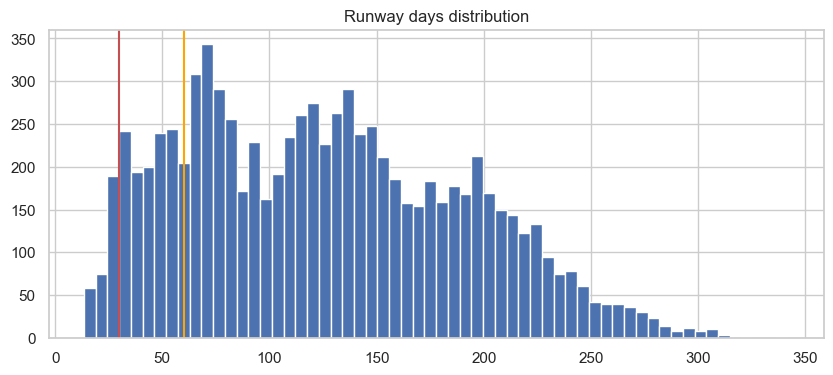

In [14]:
cf = cf.sort_values(["business_id","date"]).reset_index(drop=True)
cf["avg_out_30d"] = cf.groupby("business_id").total_cash_outflow_egp.transform(lambda s: s.rolling(30).mean())
cf["runway_days"] = cf.closing_cash_balance_egp / cf.avg_out_30d
cf["shortage_30"] = (cf.runway_days < 30).astype(int)
cf["shortage_60"] = (cf.runway_days < 60).astype(int)
print(cf[["shortage_30","shortage_60"]].mean().round(3))
print(cf.groupby("business_id")[["shortage_30","shortage_60"]].mean().round(3))
cf.runway_days.hist(bins=60); plt.title("Runway days distribution"); plt.axvline(30, c="r"); plt.axvline(60, c="orange"); plt.show()

## 6) Time-based split (no random split!)

In [15]:
TRAIN_END, VAL_END = "2024-12-31", "2025-06-30"   # test = Jul-Dec 2025
def split_label(d): return np.where(d <= TRAIN_END, "train", np.where(d <= VAL_END, "val", "test"))
cf["split"] = split_label(cf.date)
inv["split"] = split_label(inv.invoice_date)
print(cf.split.value_counts()); print(inv.groupby("split").is_late.mean().round(3))

# Leakage guard: these columns are only known AFTER the outcome
LEAKY = ["paid_date","amount_paid_egp","payment_delay_days","status","is_late"]
print("Do NOT use as features for late-invoice prediction:", LEAKY)

split
train    5848
test     1472
val      1448
Name: count, dtype: int64
split
test     0.190
train    0.188
val      0.213
Name: is_late, dtype: float64
Do NOT use as features for late-invoice prediction: ['paid_date', 'amount_paid_egp', 'payment_delay_days', 'status', 'is_late']


## 7) Save processed data for the next step

In [16]:
import os; os.makedirs("processed", exist_ok=True)
cf.to_parquet("processed/cash_flow.parquet") if False else cf.to_csv("processed/cash_flow.csv", index=False)
inv.to_csv("processed/invoices.csv", index=False)
print("saved")

saved
